# Predicting Beijing PM2.5 Air Pollution from Weather with Machine Learning

**Environmental problem:** Fine particulate matter (PM2.5) is one of the most harmful air pollutants for human health.
Cities like Beijing (and Bangkok / Chiang Mai in Thailand) suffer severe haze episodes, especially in winter / dry season.
Emissions matter, but **weather decides whether pollution disperses or accumulates**.

**Goal:** Build and compare machine learning models that predict hourly PM2.5 concentration (µg/m³) using only
meteorological and time information, then explain *which weather conditions drive pollution*.

**Research questions**
1. How accurately can meteorological conditions predict hourly PM2.5 concentration?
2. Which machine learning model performs best for this task?
3. Which weather factors most strongly control PM2.5 levels, and how?

**Workflow:** 1) Dataset → 2) Problem definition → 3) Preprocessing → 4) Feature engineering → 5) Models (7) →
6) Hyperparameter tuning → 7) Evaluation → 8) Feature importance (SHAP) → 9) Environmental interpretation

## 0. Setup

In [1]:
import warnings, time
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import shap

RANDOM_STATE = 42
FIG_DIR = '../figures/'

# Consistent, colour-blind-safe palette
BLUE, ORANGE, AQUA, YELLOW, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985'
DIVERGING = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#eb6834'])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8985', 'axes.labelcolor': '#0b0b0b',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'font.size': 11,
})
def save(name):
    plt.savefig(FIG_DIR + name)
    plt.show()

## 1. Environmental Dataset

**Beijing PM2.5 Data** — hourly PM2.5 measured at the US Embassy in Beijing, with meteorological data from
Beijing Capital International Airport, 1 Jan 2010 – 31 Dec 2014 (43,824 hourly records).

* Original source: UCI Machine Learning Repository — Chen, S. (2015). *Beijing PM2.5* [Dataset]. https://doi.org/10.24432/C5JS49
* Kaggle mirror: https://www.kaggle.com/datasets/rupakroy/lstm-datasets-multivariate-univariate
* Reference paper: Liang, X. et al. (2015). Assessing Beijing's PM2.5 pollution: severity, weather impact, APEC and winter heating. *Proc. R. Soc. A*, 471, 20150257.

| Column | Meaning |
|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³) — **target** |
| `DEWP` | Dew point (°C) — moisture in the air |
| `TEMP` | Temperature (°C) |
| `PRES` | Air pressure (hPa) |
| `cbwd` | Combined wind direction (NE, NW, SE, cv = calm/variable) |
| `Iws` | Cumulated wind speed (m/s) — hours of continuous wind in the same direction |
| `Is` | Cumulated hours of snow |
| `Ir` | Cumulated hours of rain |

In [2]:
df_raw = pd.read_csv('../data/beijing_pm25.csv')
print(df_raw.shape)
df_raw.head()

(43824, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [3]:
df_raw.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
No,43824.0,21912.5,12651.0,1.0,10956.8,21912.5,32868.2,43824.0
year,43824.0,2012.0,1.4,2010.0,2011.0,2012.0,2013.0,2014.0
month,43824.0,6.5,3.4,1.0,4.0,7.0,10.0,12.0
day,43824.0,15.7,8.8,1.0,8.0,16.0,23.0,31.0
hour,43824.0,11.5,6.9,0.0,5.8,11.5,17.2,23.0
pm2.5,41757.0,98.6,92.1,0.0,29.0,72.0,137.0,994.0
DEWP,43824.0,1.8,14.4,-40.0,-10.0,2.0,15.0,28.0
TEMP,43824.0,12.4,12.2,-19.0,2.0,14.0,23.0,42.0
PRES,43824.0,1016.4,10.3,991.0,1008.0,1016.0,1025.0,1046.0
Iws,43824.0,23.9,50.0,0.4,1.8,5.4,21.9,585.6


In [4]:
print('Missing values per column:')
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
print(f"\nPM2.5 missing: {df_raw['pm2.5'].isna().mean():.1%}")

Missing values per column:
pm2.5    2067
dtype: int64

PM2.5 missing: 4.7%


## 2. Problem Definition

* **Task type:** Supervised **regression**
* **Target (y):** hourly PM2.5 concentration (µg/m³)
* **Features (X):** weather + calendar/time variables only. Past PM2.5 values are deliberately **not** used, so the model
  must learn the *weather → pollution* relationship (this is what makes the model useful for environmental interpretation).
* **Validation design:** time-based split — train on **2010–2013**, test on **2014** (a year the model has never seen).
  A random split would leak information between neighbouring hours and overstate accuracy.
* **Metrics:** R² (variance explained), RMSE and MAE (µg/m³).

For context: the WHO 24-hour guideline for PM2.5 is **15 µg/m³**; Thailand's 24-hour standard is **37.5 µg/m³**.

### Exploratory data analysis

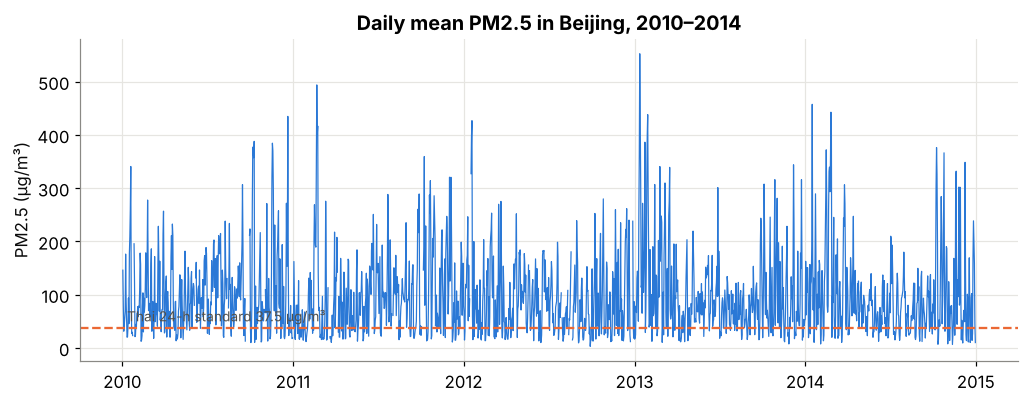

Days above Thai standard: 77%


In [5]:
df_raw['datetime'] = pd.to_datetime(df_raw[['year', 'month', 'day', 'hour']])
eda = df_raw.set_index('datetime')

fig, ax = plt.subplots(figsize=(11, 3.8))
daily = eda['pm2.5'].resample('D').mean()
ax.plot(daily.index, daily, color=BLUE, lw=0.8)
ax.axhline(37.5, color=ORANGE, lw=1.5, ls='--')
ax.text(daily.index[10], 50, 'Thai 24-h standard 37.5 µg/m³', color='#52514e', fontsize=9)
ax.set_title('Daily mean PM2.5 in Beijing, 2010–2014')
ax.set_ylabel('PM2.5 (µg/m³)')
save('01_pm25_timeseries.png')
print(f"Days above Thai standard: {(daily > 37.5).mean():.0%}")

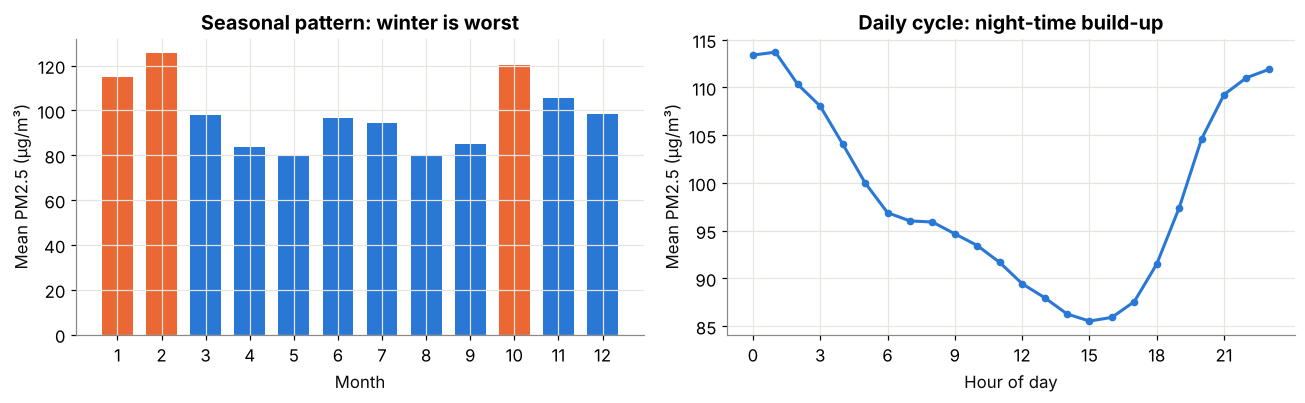

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
m = eda.groupby('month')['pm2.5'].mean()
axes[0].bar(m.index, m.values, color=[ORANGE if v > 110 else BLUE for v in m.values], width=0.7)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel('Month'); axes[0].set_ylabel('Mean PM2.5 (µg/m³)')
axes[0].set_title('Seasonal pattern: winter is worst')
h = eda.groupby('hour')['pm2.5'].mean()
axes[1].plot(h.index, h.values, color=BLUE, lw=2, marker='o', ms=4)
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel('Hour of day'); axes[1].set_ylabel('Mean PM2.5 (µg/m³)')
axes[1].set_title('Daily cycle: night-time build-up')
plt.tight_layout()
save('02_seasonal_daily_pattern.png')

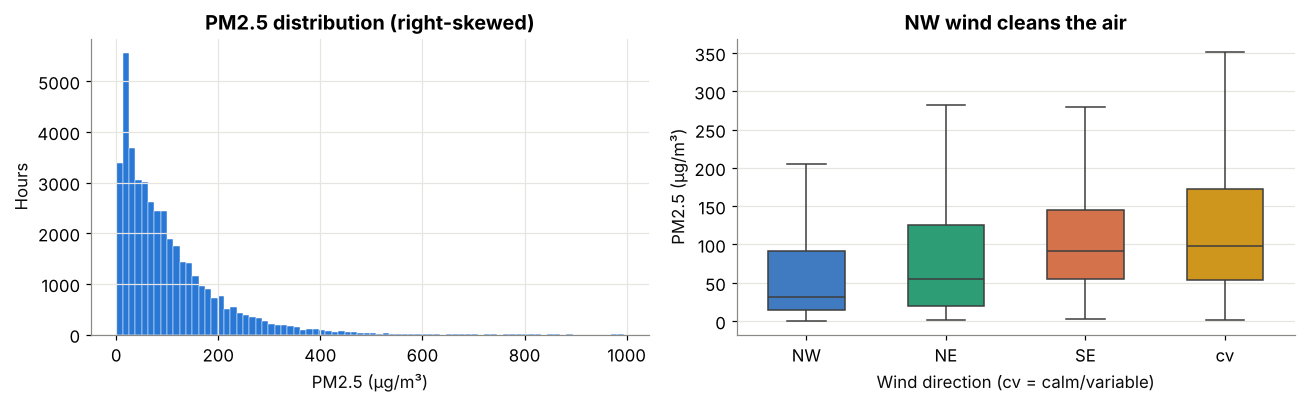

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(eda['pm2.5'].dropna(), bins=80, color=BLUE, edgecolor='white', linewidth=0.3)
axes[0].set_xlabel('PM2.5 (µg/m³)'); axes[0].set_ylabel('Hours'); axes[0].set_title('PM2.5 distribution (right-skewed)')
order = ['NW', 'NE', 'SE', 'cv']
sns.boxplot(data=eda, x='cbwd', y='pm2.5', order=order, ax=axes[1], showfliers=False,
            palette=[BLUE, AQUA, ORANGE, YELLOW], width=0.55)
axes[1].set_xlabel('Wind direction (cv = calm/variable)'); axes[1].set_ylabel('PM2.5 (µg/m³)')
axes[1].set_title('NW wind cleans the air')
plt.tight_layout()
save('03_distribution_wind.png')

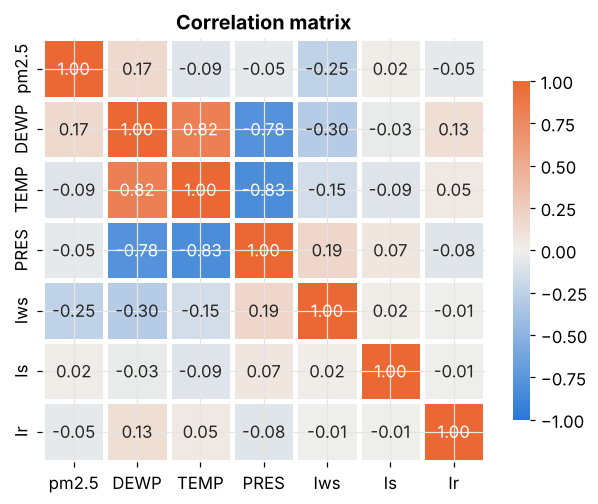

In [8]:
num = ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(eda[num].corr(), annot=True, fmt='.2f', cmap=DIVERGING, vmin=-1, vmax=1, ax=ax,
            linewidths=2, linecolor='white', cbar_kws={'shrink': 0.8})
ax.set_title('Correlation matrix')
save('04_correlation.png')

## 3. Data Preparation / Preprocessing

1. Build a proper `datetime` index and sort chronologically.
2. **Target missing values (4.7%)** — rows with missing PM2.5 are *removed* rather than imputed: inventing target values would bias evaluation.
   (They are kept until after rolling features are computed, so weather history stays continuous.)
3. One-hot encode wind direction `cbwd`.
4. Cyclical encoding for hour and month (sin/cos) so 23:00 is close to 00:00 and December close to January.
5. Scaling (`StandardScaler`) is applied inside pipelines only for scale-sensitive models (Linear Regression, KNN).

In [9]:
df = df_raw.drop(columns=['No']).set_index('datetime').sort_index()
assert df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta('1h')).all()
print('Continuous hourly index:', df.index.min(), '→', df.index.max())

Continuous hourly index: 2010-01-01 00:00:00 → 2014-12-31 23:00:00


## 4. Feature Engineering

Physically motivated features that describe **atmospheric stagnation** (the main cause of haze build-up):

| Feature | Physical meaning |
|---|---|
| `RH` | Relative humidity from TEMP & DEWP (Magnus formula) — humid air helps secondary aerosol formation |
| `dew_spread` | TEMP − DEWP; small spread = moist, stable air |
| `DEWP_24h`, `DEWP_72h` | Moisture history over the last 1–3 days |
| `Iws_24h`, `Iws_72h` | Ventilation over the last 1–3 days |
| `PRES_24h`, `PRES_chg24` | Pressure level and 24-h change (passing weather fronts) |
| `TEMP_24h`, `RH_24h` | Smoothed thermal/humidity conditions |
| `hrs_since_NW` | Hours since the last clean north-westerly wind — how long pollution has been accumulating |
| `rain_24h` | Any rain in the last 24 h (wet deposition / washout) |
| `hour_sin/cos`, `month_sin/cos`, `dayofweek` | Daily, seasonal and weekly human-activity cycles |

All features use only current and **past** weather, so there is no information leakage from the future.

In [10]:
def magnus_rh(temp, dewp):
    a, b = 17.625, 243.04
    return 100 * np.exp(a * dewp / (b + dewp)) / np.exp(a * temp / (b + temp))

df['RH'] = magnus_rh(df['TEMP'], df['DEWP']).clip(0, 100)
df['dew_spread'] = df['TEMP'] - df['DEWP']
for col in ['DEWP', 'Iws', 'PRES', 'TEMP', 'RH']:
    df[f'{col}_24h'] = df[col].rolling(24, min_periods=1).mean()
for col in ['DEWP', 'Iws']:
    df[f'{col}_72h'] = df[col].rolling(72, min_periods=1).mean()
df['PRES_chg24'] = df['PRES'].diff(24)
df['rain_24h'] = (df['Ir'].rolling(24, min_periods=1).max() > 0).astype(int)

is_nw = (df['cbwd'] == 'NW').astype(int)
df['hrs_since_NW'] = is_nw.groupby(is_nw.cumsum()).cumcount().where(is_nw == 0, 0).clip(upper=240)

df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24); df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12); df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['dayofweek'] = df.index.dayofweek
df = pd.get_dummies(df, columns=['cbwd'], prefix='wind', dtype=int)

# Now drop rows without a target (and the first 24 h without pressure change)
df = df.dropna(subset=['pm2.5', 'PRES_chg24'])
print('Modelling dataset:', df.shape)

Modelling dataset: (41757, 32)


In [11]:
BASE_FEATURES = ['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv',
                 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dayofweek']
ENGINEERED = ['RH', 'dew_spread', 'DEWP_24h', 'DEWP_72h', 'Iws_24h', 'Iws_72h', 'PRES_24h', 'PRES_chg24',
              'TEMP_24h', 'RH_24h', 'hrs_since_NW', 'rain_24h']
FEATURES = BASE_FEATURES + ENGINEERED
TARGET = 'pm2.5'

train, test = df[df['year'] < 2014], df[df['year'] == 2014]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f'Train (2010–2013): {len(train):,} hours | Test (2014): {len(test):,} hours | Features: {len(FEATURES)}')

Train (2010–2013): 33,096 hours | Test (2014): 8,661 hours | Features: 27


## 5. Build Multiple ML Models (7 models)

| # | Model | Family |
|---|---|---|
| 1 | Linear Regression | Linear baseline |
| 2 | K-Nearest Neighbours | Instance-based |
| 3 | Decision Tree | Single tree |
| 4 | Random Forest | Bagging ensemble |
| 5 | Histogram Gradient Boosting | Boosting ensemble (scikit-learn) |
| 6 | XGBoost | Boosting ensemble |
| 7 | LightGBM | Boosting ensemble |

All models are first trained with default / sensible settings.

In [12]:
def evaluate(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred)}

models = {
    'Linear Regression': Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]),
    'KNN': Pipeline([('scale', StandardScaler()), ('model', KNeighborsRegressor(n_neighbors=15, n_jobs=-1))]),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=400, learning_rate=0.05, random_state=RANDOM_STATE, n_jobs=-1),
    'LightGBM': LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1),
}

baseline_results, fitted = [], {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    res = evaluate(y_test, model.predict(X_test))
    res.update(Model=name, Seconds=round(time.time() - t0, 1))
    baseline_results.append(res); fitted[name] = model
baseline_df = pd.DataFrame(baseline_results).set_index('Model').sort_values('R2', ascending=False)
baseline_df.round(3)

,R2,RMSE,MAE,Seconds
Model,,,,
LightGBM,0.561,61.991,41.839,0.8
Hist Gradient Boosting,0.558,62.164,42.089,0.6
XGBoost,0.557,62.282,42.324,1.0
Random Forest,0.534,63.834,44.589,30.4
KNN,0.490,66.779,46.610,0.6
Linear Regression,0.468,68.190,47.540,0.1
Decision Tree,0.344,75.724,51.456,0.3


### Does feature engineering help?
Same LightGBM model trained with raw variables only vs. raw + engineered features.

,n_features,R2,RMSE,MAE
Feature set,,,,
Raw features only,15,0.469,68.158,46.465
Raw + engineered,27,0.561,61.991,41.839


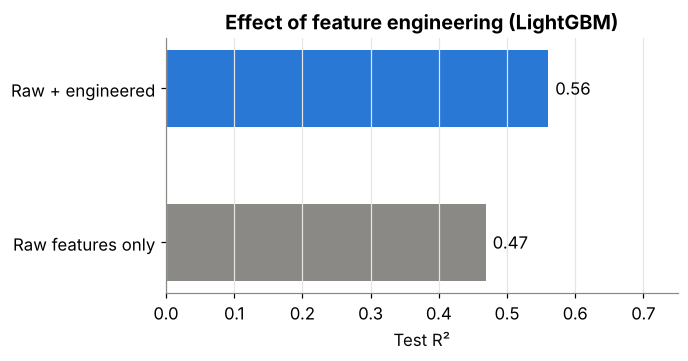

In [13]:
fe_rows = []
for label, feats in [('Raw features only', BASE_FEATURES), ('Raw + engineered', FEATURES)]:
    m = LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1)
    m.fit(train[feats], y_train)
    fe_rows.append({'Feature set': label, 'n_features': len(feats), **evaluate(y_test, m.predict(test[feats]))})
fe_df = pd.DataFrame(fe_rows).set_index('Feature set')
display(fe_df.round(3))

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(fe_df.index, fe_df['R2'], color=[GREY, BLUE], height=0.5)
for i, v in enumerate(fe_df['R2']):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
ax.set_xlim(0, 0.75); ax.set_xlabel('Test R²'); ax.set_title('Effect of feature engineering (LightGBM)')
ax.grid(axis='y', visible=False)
save('05_feature_engineering_effect.png')

## 6. Hyperparameter Tuning

The three strongest model families are tuned with `RandomizedSearchCV` using **`TimeSeriesSplit` (3 folds)** on the
training years only, so the test year 2014 is never touched during tuning.

In [14]:
tscv = TimeSeriesSplit(n_splits=3)
search_spaces = {
    'Random Forest': (RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE), {
        'n_estimators': [150, 250],
        'max_depth': [12, 18, 25, None],
        'min_samples_leaf': [1, 3, 5, 10],
        'max_features': ['sqrt', 0.33, 0.5],
    }, 8),
    'XGBoost': (XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        'n_estimators': [300, 500, 800],
        'learning_rate': [0.02, 0.03, 0.05, 0.1],
        'max_depth': [4, 6, 8],
        'subsample': [0.7, 0.85, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'min_child_weight': [1, 5, 10],
    }, 15),
    'LightGBM': (LGBMRegressor(random_state=RANDOM_STATE, verbose=-1), {
        'n_estimators': [300, 500, 800],
        'learning_rate': [0.02, 0.03, 0.05, 0.1],
        'num_leaves': [15, 31, 63],
        'min_child_samples': [10, 20, 50],
        'subsample': [0.7, 0.85, 1.0], 'subsample_freq': [1],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'reg_lambda': [0, 1, 5],
    }, 15),
}

tuned, tuned_results, best_params = {}, [], {}
for name, (est, grid, n_iter) in search_spaces.items():
    t0 = time.time()
    search = RandomizedSearchCV(est, grid, n_iter=n_iter, cv=tscv, scoring='r2',
                                random_state=RANDOM_STATE, n_jobs=1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    best_params[name] = search.best_params_
    res = evaluate(y_test, search.best_estimator_.predict(X_test))
    res.update(Model=f'{name} (tuned)', CV_R2=search.best_score_, Seconds=round(time.time() - t0, 1))
    tuned_results.append(res)
    print(f'{name}: CV R² = {search.best_score_:.3f} | best params = {search.best_params_}')

Random Forest: CV R² = 0.513 | best params = {'n_estimators': 250, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}


XGBoost: CV R² = 0.517 | best params = {'subsample': 0.85, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


LightGBM: CV R² = 0.533 | best params = {'subsample_freq': 1, 'subsample': 0.85, 'reg_lambda': 1, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 20, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


## 7. Model Evaluation

In [15]:
all_results = pd.concat([baseline_df.drop(columns='Seconds'),
                         pd.DataFrame(tuned_results).set_index('Model')[['R2', 'RMSE', 'MAE']]])
all_results = all_results.sort_values('R2', ascending=False)
all_results.to_csv('../figures/model_results.csv')
all_results.round(3)

,R2,RMSE,MAE
Model,,,
LightGBM (tuned),0.576,60.901,41.280
XGBoost (tuned),0.567,61.508,41.826
LightGBM,0.561,61.991,41.839
Hist Gradient Boosting,0.558,62.164,42.089
XGBoost,0.557,62.282,42.324
Random Forest (tuned),0.551,62.662,43.209
Random Forest,0.534,63.834,44.589
KNN,0.490,66.779,46.610
Linear Regression,0.468,68.190,47.540


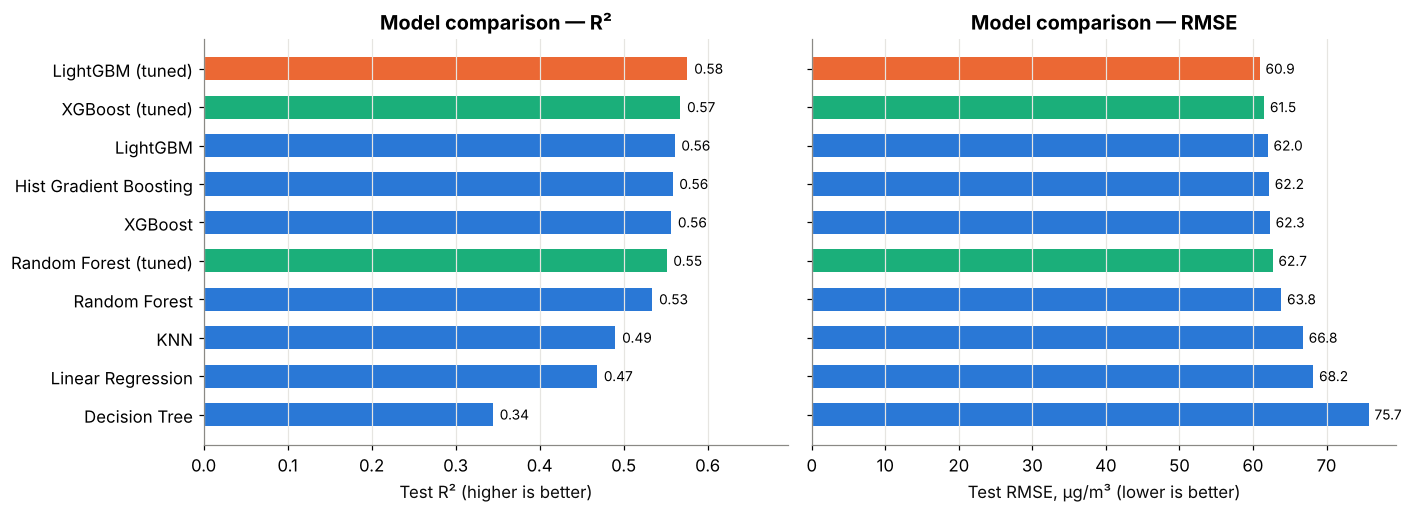

Best model: LightGBM (tuned)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
r = all_results.sort_values('R2')
best_name = r.index[-1]
colors = [ORANGE if n == best_name else (AQUA if 'tuned' in n else BLUE) for n in r.index]
axes[0].barh(r.index, r['R2'], color=colors, height=0.6)
for i, v in enumerate(r['R2']):
    axes[0].text(v + 0.008, i, f'{v:.2f}', va='center', fontsize=9)
axes[0].set_xlim(0, max(r['R2']) + 0.12); axes[0].set_xlabel('Test R² (higher is better)')
axes[0].set_title('Model comparison — R²'); axes[0].grid(axis='y', visible=False)
axes[1].barh(r.index, r['RMSE'], color=colors, height=0.6)
for i, v in enumerate(r['RMSE']):
    axes[1].text(v + 0.8, i, f'{v:.1f}', va='center', fontsize=9)
axes[1].set_xlabel('Test RMSE, µg/m³ (lower is better)'); axes[1].set_title('Model comparison — RMSE')
axes[1].set_yticklabels([]); axes[1].grid(axis='y', visible=False)
plt.tight_layout()
save('06_model_comparison.png')
print('Best model:', best_name)

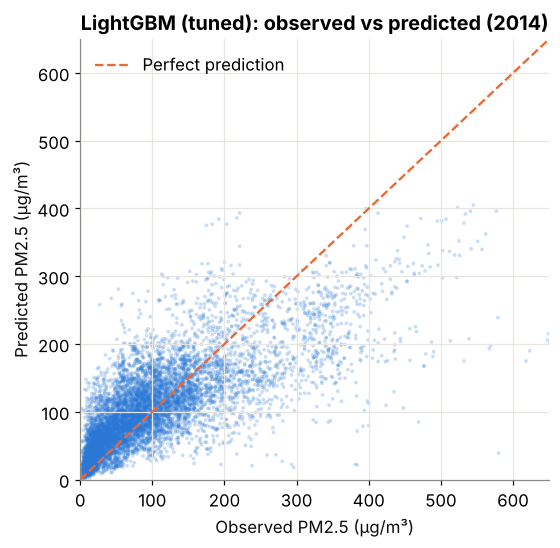

In [17]:
best_key = best_name.replace(' (tuned)', '')
best_model = tuned.get(best_key, fitted.get(best_key))
y_pred = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.scatter(y_test, y_pred, s=6, alpha=0.25, color=BLUE, edgecolors='none')
lim = [0, 650]
ax.plot(lim, lim, color=ORANGE, lw=1.5, ls='--', label='Perfect prediction')
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel('Observed PM2.5 (µg/m³)'); ax.set_ylabel('Predicted PM2.5 (µg/m³)')
ax.set_title(f'{best_name}: observed vs predicted (2014)'); ax.legend(frameon=False)
save('07_observed_vs_predicted.png')

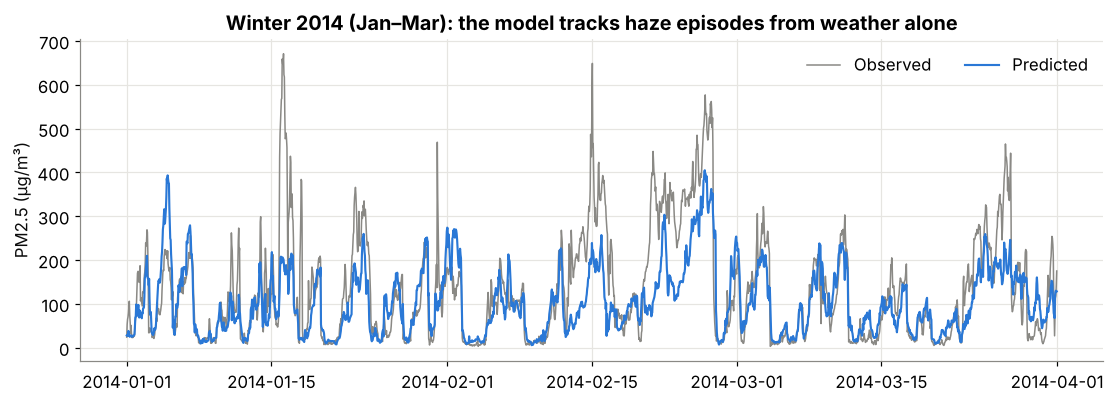

In [18]:
window = slice('2014-01-01', '2014-03-31')
s_obs = y_test.loc[window]; s_pred = pd.Series(y_pred, index=y_test.index).loc[window]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(s_obs.index, s_obs, color=GREY, lw=1, label='Observed')
ax.plot(s_pred.index, s_pred, color=BLUE, lw=1.4, label='Predicted')
ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_title('Winter 2014 (Jan–Mar): the model tracks haze episodes from weather alone')
ax.legend(frameon=False, ncol=2, loc='upper right')
save('08_timeseries_prediction.png')

In [19]:
# Can the model flag unhealthy hours? (PM2.5 > 75 µg/m³)
thr = 75
obs_bad, pred_bad = y_test > thr, y_pred > thr
acc = (obs_bad == pred_bad).mean()
recall = (obs_bad & pred_bad).sum() / obs_bad.sum()
precision = (obs_bad & pred_bad).sum() / pred_bad.sum()
print(f'Hours > {thr} µg/m³ — accuracy {acc:.1%}, recall {recall:.1%}, precision {precision:.1%}')

Hours > 75 µg/m³ — accuracy 79.3%, recall 90.6%, precision 72.8%


## 8. Feature Importance (Explainable ML)

Two complementary methods on the best model:
* **Permutation importance** (model-agnostic): how much test R² drops when a feature is shuffled.
* **SHAP values**: how much each feature pushes an individual prediction up or down, and in which direction.

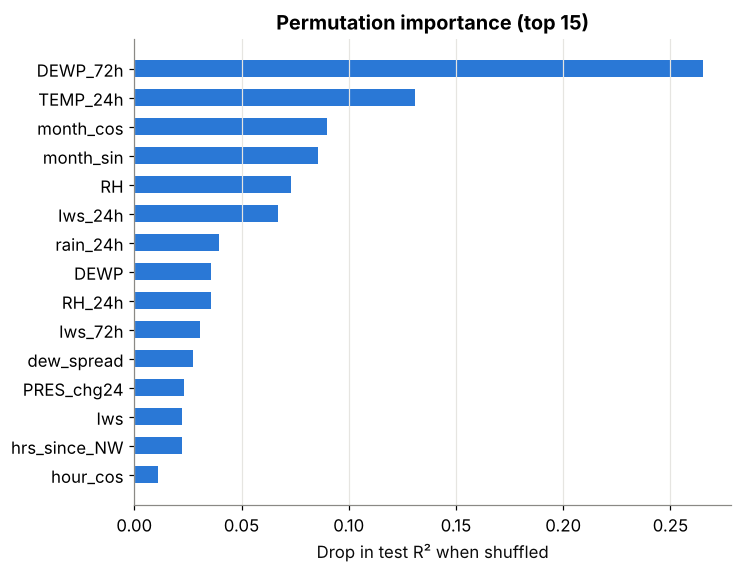

In [20]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring='r2', n_jobs=1)
perm_df = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(perm_df.index, perm_df.values, color=BLUE, height=0.6)
ax.set_xlabel('Drop in test R² when shuffled'); ax.set_title('Permutation importance (top 15)')
ax.grid(axis='y', visible=False)
save('09_permutation_importance.png')

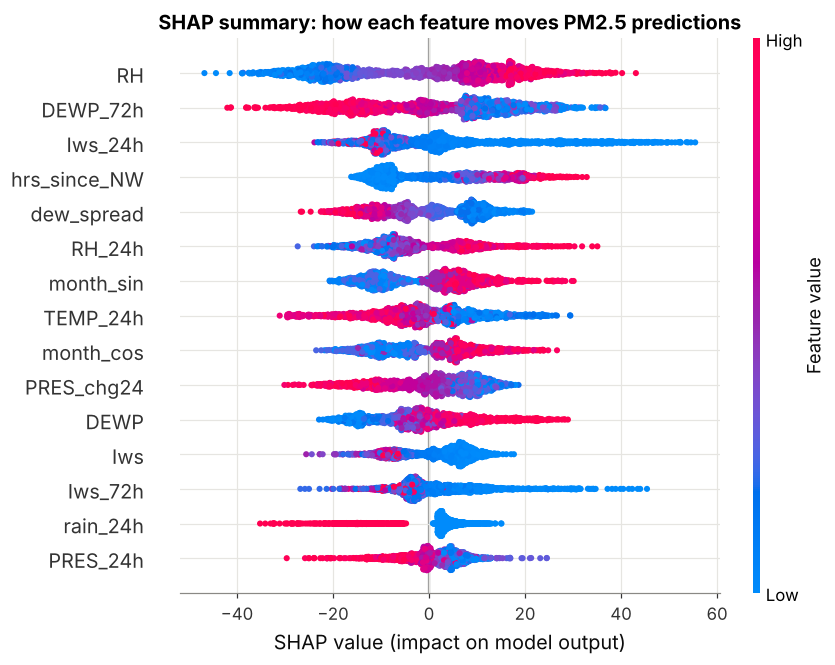

In [21]:
X_shap = X_test.sample(2000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)

plt.figure()
shap.summary_plot(shap_values, X_shap, max_display=15, show=False, plot_size=(8, 6))
plt.title('SHAP summary: how each feature moves PM2.5 predictions')
save('10_shap_summary.png')

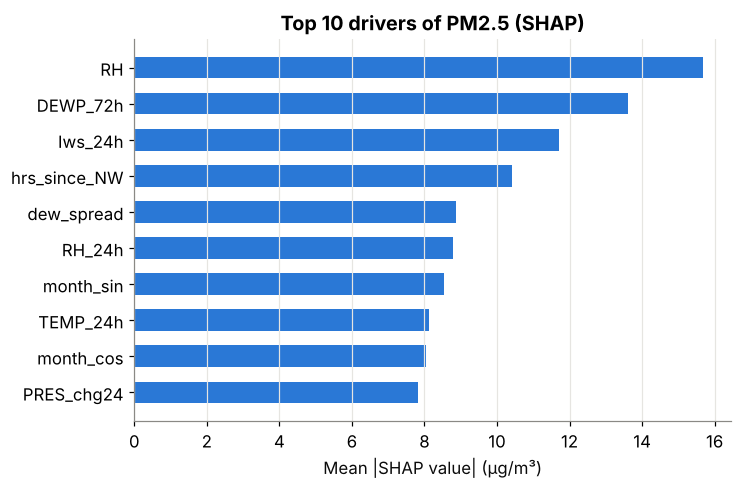

RH              15.7
DEWP_72h        13.6
Iws_24h         11.7
hrs_since_NW    10.4
dew_spread       8.9
RH_24h           8.8
month_sin        8.5
TEMP_24h         8.1
month_cos        8.0
PRES_chg24       7.8
dtype: float64

In [22]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=True).tail(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(mean_abs.index, mean_abs.values, color=BLUE, height=0.6)
ax.set_xlabel('Mean |SHAP value| (µg/m³)'); ax.set_title('Top 10 drivers of PM2.5 (SHAP)')
ax.grid(axis='y', visible=False)
save('11_shap_top10.png')
mean_abs.sort_values(ascending=False).round(1)

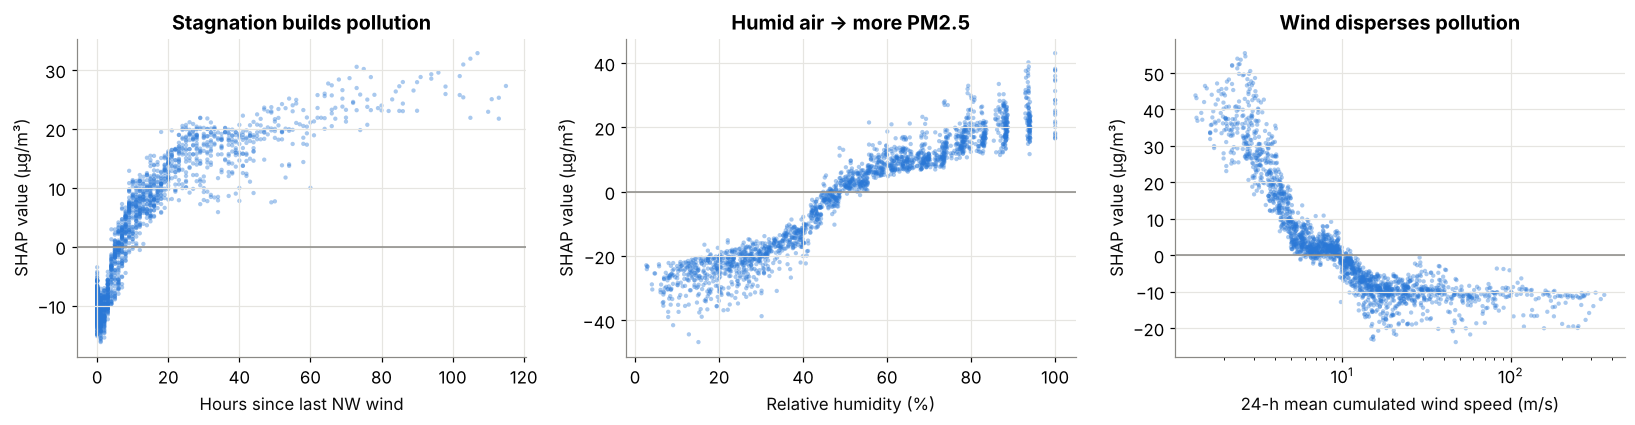

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat, label in zip(axes, ['hrs_since_NW', 'RH', 'Iws_24h'],
                           ['Hours since last NW wind', 'Relative humidity (%)', '24-h mean cumulated wind speed (m/s)']):
    i = FEATURES.index(feat)
    ax.scatter(X_shap[feat], shap_values[:, i], s=8, alpha=0.4, color=BLUE, edgecolors='none')
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xlabel(label); ax.set_ylabel('SHAP value (µg/m³)')
axes[2].set_xscale('log')
axes[0].set_title('Stagnation builds pollution'); axes[1].set_title('Humid air → more PM2.5'); axes[2].set_title('Wind disperses pollution')
plt.tight_layout()
save('12_shap_dependence.png')

## 9. Environmental Interpretation

Summary printed from the results above, followed by interpretation.

In [24]:
print('BEST MODEL:', best_name)
print(all_results.loc[best_name].round(3).to_string())
print('\nTop 5 SHAP drivers:', ', '.join(mean_abs.sort_values(ascending=False).index[:5]))
print('\nMean PM2.5 by wind direction:')
print(df_raw.groupby('cbwd')['pm2.5'].mean().round(0).sort_values().to_string())

BEST MODEL: LightGBM (tuned)
R2       0.576
RMSE    60.901
MAE     41.280

Top 5 SHAP drivers: RH, DEWP_72h, Iws_24h, hrs_since_NW, dew_spread

Mean PM2.5 by wind direction:
cbwd
NW     70.0
NE     90.0
SE    111.0
cv    126.0


**Key findings**

1. **Weather alone explains about 58% of the hour-to-hour variation in PM2.5** in an unseen year (tuned LightGBM:
   R² = 0.58, RMSE ≈ 61 µg/m³, MAE ≈ 41 µg/m³). Tree-based boosting ensembles (LightGBM, XGBoost) clearly beat linear
   regression, KNN and a single decision tree, because the weather–pollution relationship is strongly **non-linear**
   with interactions (e.g. calm + humid + winter). Tuning added ~1.5 R² points; physically based feature engineering
   added ~9 points (0.47 → 0.56), the biggest single gain.
2. **Humidity is the #1 driver.** High relative humidity (`RH`) pushes PM2.5 up strongly: moist air promotes secondary
   aerosol formation (sulfate, nitrate) and hygroscopic particle growth, and humid southerly air masses carry regional
   pollution. Conversely a large `dew_spread` (dry air) means cleaner air.
3. **Atmospheric stagnation builds pollution.** The longer since the last north-westerly wind (`hrs_since_NW`) and the
   lower the accumulated wind (`Iws_24h`), the higher PM2.5 — pollution is not removed and accumulates over days
   (SHAP rises steeply during the first ~24–36 h of stagnation).
4. **Clean-air mechanisms:** rain in the last 24 h (`rain_24h`, wet deposition) and rising pressure (`PRES_chg24`,
   arrival of a cold front) both lower PM2.5. A high 3-day dew point (`DEWP_72h`, summer monsoon air) is also linked
   to lower PM2.5.
5. **Wind direction matters:** NW winds bring clean, dry air from Mongolia (mean ≈ 70 µg/m³), while SE winds
   (≈ 111 µg/m³) and calm conditions (≈ 126 µg/m³) bring or trap polluted air from the North China Plain.
6. **Seasonality and time of day:** winter (coal heating + temperature inversions) and night-time (shallow boundary layer)
   have the highest concentrations; 77% of days exceeded Thailand's 24-h standard of 37.5 µg/m³.
7. **Early warning:** as a warning tool for unhealthy hours (> 75 µg/m³) the model catches ~91% of them (recall) with ~73% precision.

**Implications**
* Weather-based ML can provide **early warning of haze episodes** a day ahead using weather forecasts, supporting
  health advisories, school closures or temporary emission controls before a stagnation event.
* Emission control should be **intensified during forecast stagnant, humid periods** — the same emissions are far more
  harmful under those conditions.
* The same workflow can be applied to Thai cities (Bangkok, Chiang Mai) where dry-season stagnation and biomass burning drive PM2.5.

**Limitations:** no emission data (traffic, heating, fires) and no past PM2.5 in the features; a single monitoring station;
remaining ~40% unexplained variance reflects emissions and regional transport not captured by local weather.